#Lab - 12
#Deep Learning in Vision

Classification, Detection,Segmentation and Vision Transformers

In [ ]:
pip install torchvision ultralytics segmentation-models-pytorch

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 15.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.6/876.6 kB 63.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 27.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 60.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.0 MB/s eta 0:00:00


##Experiment 1 — Setting Up the Pretrained Models

In [ ]:
import time
import random
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import torchvision
import torchvision.transforms.functional as TF

device = "cuda" if torch.cuda.is_available() else "cpu"
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

print("torch ", torch.__version__)
print("torchvision", torchvision.__version__)
print("device :", device)

torch  2.14.1+cpu
torchvision 0.29.1+cpu
device : cpu


In [ ]:
def iou(box_a, box_b):
    """Boxes as [x1, y1, x2, y2]."""
    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])
    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])
    inter = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
    return inter / (area_a + area_b - inter)

def dice(pred_count, true_count, intersection):
    return 2 * intersection / (pred_count + true_count)

def iou_from_counts(pred_count, true_count, intersection):
    return intersection / (pred_count + true_count - intersection)

print(f"IoU of two boxes : {iou([2, 2, 8, 7], [4, 3, 10, 8]):.4f}")
print(f"Dice of two masks : {dice(80, 100, 70):.4f}")
print(f"IoU of the same : {iou_from_counts(80, 100, 70):.4f}")

IoU of two boxes : 0.3636
Dice of two masks : 0.7778
IoU of the same : 0.6364


##Experiment 2 — Classification with a Pretrained ResNet and ViT

In [ ]:
from torchvision.models import (resnet50, ResNet50_Weights,
                                vit_b_16, ViT_B_16_Weights)

IMAGENETTE_TO_IMAGENET = [0, 217, 482, 491, 497, 566, 569, 571, 574, 701]

zoo = {
    "ResNet-50": (resnet50(weights=ResNet50_Weights.IMAGENET1K_V2),
                  ResNet50_Weights.IMAGENET1K_V2),
    "ViT-B/16": (vit_b_16(weights=ViT_B_16_Weights.IMAGENET1K_V1),
                 ViT_B_16_Weights.IMAGENET1K_V1),
}

for name, (net, w) in zoo.items():
    n_params = sum(p.numel() for p in net.parameters())
    size = w.transforms().crop_size[0]
    print(f"{name:10s} {n_params:>12,} parameters input {size} x {size}")

ResNet-50    25,557,032 parameters input 224 x 224
ViT-B/16     86,567,656 parameters input 224 x 224


In [ ]:
from torchvision.datasets import Imagenette

def evaluate(name, n_images=500):
    net, w = zoo[name]
    net = net.to(device).eval()
    data = Imagenette("data", split="val", size="160px", download=True,
                      transform=w.transforms())
    g = torch.Generator().manual_seed(0)
    chosen = torch.randperm(len(data), generator=g)[:n_images].tolist()
    keep = torch.tensor(IMAGENETTE_TO_IMAGENET, device=device)
    correct = 0
    t0 = time.perf_counter()
    with torch.no_grad():
        for start in range(0, n_images, 50):
            batch = [data[i] for i in chosen[start:start + 50]]
            x = torch.stack([b[0] for b in batch]).to(device)
            y = torch.tensor([b[1] for b in batch], device=device)
            scores = net(x)[:, keep]
            correct += (scores.argmax(dim=1) == y).sum().item()
    ms = (time.perf_counter() - t0) / n_images * 1e3
    return correct / n_images, ms

print(f"{'model':10s} {'top-1':>8} {'ms/image':>10}")
for name in zoo:
    acc, ms = evaluate(name)
    print(f"{name:10s} {acc:>8.1%} {ms:>10.1f}")

model         top-1   ms/image
ResNet-50    100.0%      287.5
ViT-B/16     100.0%      819.0


In [ ]:
net, w = zoo["ResNet-50"]
net = net.to(device).eval()
data = Imagenette("data", split="val", size="160px", transform=w.transforms())
names = w.meta["categories"]
x, y = data[0]
with torch.no_grad():
    p = torch.softmax(net(x.unsqueeze(0).to(device)), dim=1)[0]
print("true class:", names[IMAGENETTE_TO_IMAGENET[y]])
for prob, k in zip(*p.topk(5)):
    print(f"{prob.item():7.4f} {names[k]}")
print("sum of all 1000 probabilities:", round(p.sum().item(), 4))

true class: tench
 0.5997 tench
 0.0057 shovel
 0.0049 tank
 0.0048 assault rifle
 0.0038 barracouta
sum of all 1000 probabilities: 1.0


In [ ]:
import copy
from torch.utils.data import DataLoader, Subset

def new_head(name, net):
    """Replace the 1,000-way output layer by a new 10-way layer and return it."""
    if name == "ResNet-50":
        net.fc = nn.Linear(net.fc.in_features, 10)
        return net.fc
    net.heads.head = nn.Linear(net.heads.head.in_features, 10)
    return net.heads.head

def finetune(name, full, train_n=1000, epochs=2):
    """Fine-tune a copy of a pretrained model on Imagenette's training images.
    full=False trains only the new layer; full=True trains every weight."""
    pretrained, w = zoo[name]
    net = copy.deepcopy(pretrained).cpu()
    head = new_head(name, net)
    for p in net.parameters():
        p.requires_grad = full
    for p in head.parameters():
        p.requires_grad = True
    net = net.to(device)
    params = [p for p in net.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=1e-4 if full else 1e-3)
    loss_fn = nn.CrossEntropyLoss()
    data = Imagenette("data", split="train", size="160px", download=True,
                      transform=w.transforms())
    g = torch.Generator().manual_seed(0)
    chosen = torch.randperm(len(data), generator=g)[:train_n].tolist()
    loader = DataLoader(Subset(data, chosen), batch_size=16, shuffle=True)
    t0 = time.perf_counter()
    for epoch in range(epochs):
        net.train(full)
        running = 0.0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(net(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
            running += loss.item() * len(x)
    secs = time.perf_counter() - t0
    n_train = sum(p.numel() for p in params)
    return net, w, n_train, running / train_n, secs

def evaluate_ft(net, w, n_images=500):
    """Top-1 accuracy of the 10-way model on the same 500 validation images."""
    data = Imagenette("data", split="val", size="160px", transform=w.transforms())
    g = torch.Generator().manual_seed(0)
    chosen = torch.randperm(len(data), generator=g)[:n_images].tolist()
    net.eval()
    correct = 0
    with torch.no_grad():
        for start in range(0, n_images, 50):
            batch = [data[i] for i in chosen[start:start + 50]]
            x = torch.stack([b[0] for b in batch]).to(device)
            y = torch.tensor([b[1] for b in batch], device=device)
            correct += (net(x).argmax(dim=1) == y).sum().item()
    return correct / n_images

In [ ]:
print(f"{'model':10s} {'training':8s} {'trainable':>12s} {'loss':>7s} {'val acc':>8s} {'seconds':>8s}")
for name in zoo:
    for full in (False, True):
        net, w, n_train, loss, secs = finetune(name, full)
        acc = evaluate_ft(net, w)
        print(f"{name:10s} {'full' if full else 'frozen':8s} {n_train:>12,} "
              f"{loss:>7.4f} {acc:>8.1%} {secs:>8.0f}")
        del net
        torch.cuda.empty_cache()

model      training    trainable    loss  val acc  seconds
ResNet-50  frozen         20,490  0.4460    97.8%      431
ResNet-50  full       23,528,522  0.2108    96.4%     1473
ViT-B/16   frozen          7,690  0.0356    99.6%     1498
ViT-B/16   full       85,806,346  0.0404    90.8%     4615


##Experiment 3 — Object Detection with YOLO

In [ ]:
from ultralytics import YOLO
det = YOLO("yolo11n.pt")
n_params = sum(p.numel() for p in det.model.parameters())
print("classes :", len(det.names), " e.g.", [det.names[i] for i in (0, 2, 16)])
print(f"params : {n_params / 1e6:.1f} million")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


classes : 80  e.g. ['person', 'car', 'dog']
params : 2.6 million


In [ ]:
from pathlib import Path
from ultralytics.data.utils import check_det_dataset
info = check_det_dataset("coco128.yaml")
label_dir = Path(info["path"]) / "labels" / "train2017"
files = sorted((Path(info["path"]) / "images" / "train2017").glob("*.jpg"))[:20]

def load_truth(label_file, h, w):
    """YOLO label file -> list of (class, [x1, y1, x2, y2]) in pixels."""
    boxes = []
    if label_file.exists():
        for line in label_file.read_text().splitlines():
            c, cx, cy, bw, bh = line.split()[:5]
            cx, bw = float(cx) * w, float(bw) * w
            cy, bh = float(cy) * h, float(bh) * h
            boxes.append((int(c), [cx - bw / 2, cy - bh / 2,
                                  cx + bw / 2, cy + bh / 2]))
    return boxes

n_truth = n_pred = n_match = 0
dev_results = []
best_ious = []
results = det.predict([str(f) for f in files], conf=0.25, verbose=False)
for r in results:
    h, w = r.orig_shape
    truth = load_truth(label_dir / (Path(r.path).stem + ".txt"), h, w)
    n_truth += len(truth)
    for box, cls in zip(r.boxes.xyxy.tolist(), r.boxes.cls.tolist()):
        best = max((iou(box, t) for c, t in truth if c == int(cls)), default=0.0)
        best_ious.append(best)
        n_pred += 1
        n_match += best >= 0.5
print(f"images : {len(files)}")
print(f"ground-truth boxes : {n_truth}")
print(f"predicted boxes : {n_pred} (confidence >= 0.25)")
print(f"matched at IoU 0.5 : {n_match} ({n_match / n_pred:.0%} of predictions)")
print(f"mean best IoU : {sum(best_ious) / len(best_ious):.3f}")

images : 20
ground-truth boxes : 89
predicted boxes : 75 (confidence >= 0.25)
matched at IoU 0.5 : 61 (81% of predictions)
mean best IoU : 0.706


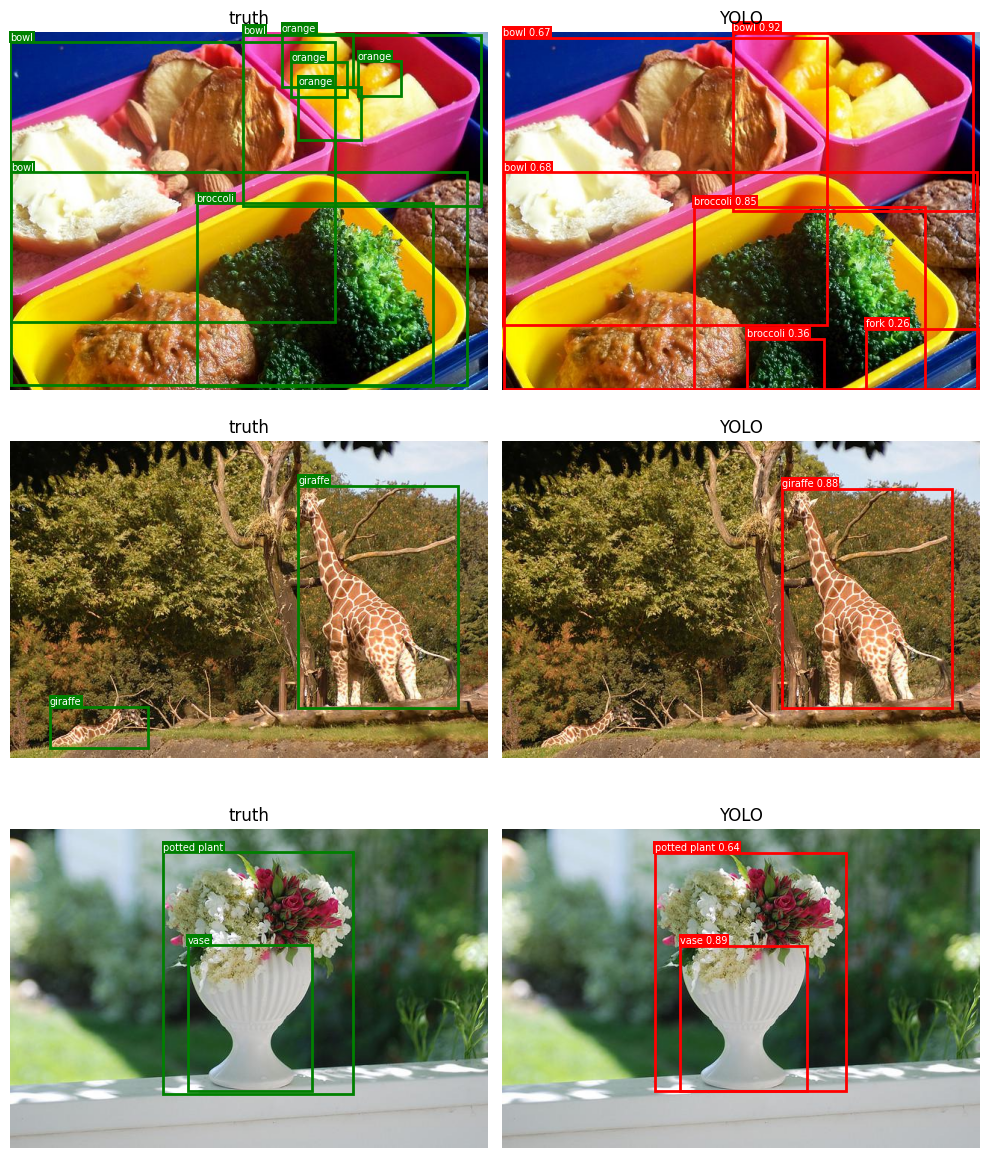

In [ ]:
import matplotlib.patches as patches

def draw_boxes(ax, boxes, labels, color):
    for (x1, y1, x2, y2), text in zip(boxes, labels):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                       fill=False, edgecolor=color, linewidth=2))
        ax.text(x1, y1 - 3, text, color="white", fontsize=7,
                bbox=dict(facecolor=color, edgecolor="none", pad=1))

def show_detections(model, n_images=3, conf=0.25):
    """Ground truth (green) beside the model's predictions (red), per image."""
    fig, axes = plt.subplots(n_images, 2, figsize=(10, 4 * n_images))
    for row, f in enumerate(files[:n_images]):
        r = model.predict(str(f), conf=conf, verbose=False)[0]
        h, w = r.orig_shape
        truth = load_truth(label_dir / (f.stem + ".txt"), h, w)
        photo = r.orig_img[..., ::-1]  # OpenCV order BGR -> RGB
        for ax, title in zip(axes[row], ("truth", "YOLO")):
            ax.imshow(photo)
            ax.set_title(title)
            ax.axis("off")
        draw_boxes(axes[row][0], [b for c, b in truth],
                   [r.names[c] for c, b in truth], "green")
        pred_labels = [f"{r.names[int(c)]} {s:.2f}"
                       for c, s in zip(r.boxes.cls.tolist(), r.boxes.conf.tolist())]
        draw_boxes(axes[row][1], r.boxes.xyxy.tolist(), pred_labels, "red")
    plt.tight_layout()
    plt.show()

show_detections(det)

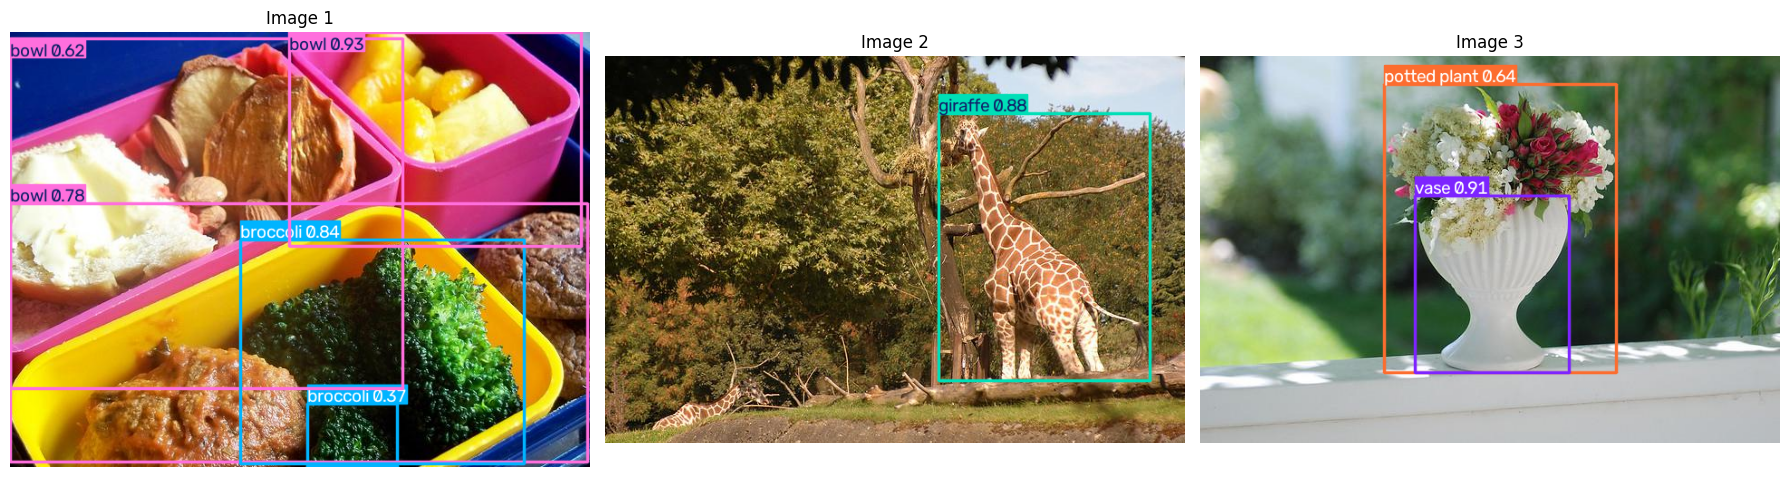

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Let's display the first 3 images with their predicted boxes
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for idx, r in enumerate(results[:3]):
    # Plot predictions using ultralytics built-in plot tool
    im_bgr = r.plot()  # returns numpy array in BGR format
    im_rgb = cv2.cvtColor(im_bgr, cv2.COLOR_BGR2RGB)

    axes[idx].imshow(im_rgb)
    axes[idx].set_title(f"Image {idx+1}")
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
for thr in (0.1, 0.5, 0.7, 0.95):
    rs = det.predict([str(f) for f in files], conf=0.25, iou=thr, verbose=False)
    total = sum(len(r.boxes) for r in rs)
    print(f"NMS threshold {thr:>4}: {total} boxes in {len(files)} images")

NMS threshold  0.1: 64 boxes in 20 images
NMS threshold  0.5: 69 boxes in 20 images
NMS threshold  0.7: 75 boxes in 20 images
NMS threshold 0.95: 152 boxes in 20 images


In [ ]:
metrics = det.val(data="coco128.yaml", plots=False, verbose=False)
print(f"mAP@0.5 : {metrics.box.map50:.3f}")
print(f"mAP@0.5:0.95 : {metrics.box.map:.3f}")

Ultralytics 8.4.183 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1087.2±364.2 MB/s, size: 50.9 KB)
val: Scanning /content/datasets/coco128/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 1.9Kit/s 0.1s
val: New cache created: /content/datasets/coco128/labels/train2017.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.0s/it 24.4s
                   all        128        929      0.663      0.589      0.671      0.503
Speed: 1.9ms preprocess, 178.5ms inference, 0.0ms loss, 3.4ms postprocess per image
mAP@0.5 : 0.671
mAP@0.5:0.95 : 0.503


In [ ]:
ft = YOLO("yolo11n.pt")
ft.train(data="coco128.yaml", epochs=5, imgsz=640, batch=16,
         freeze=10, optimizer="AdamW", lr0=1e-4,
         project="runs", name="coco128_ft", exist_ok=True,
         plots=False, verbose=False)
best = YOLO(str(ft.trainer.best))
after = best.val(data="coco128.yaml", plots=False, verbose=False)
print(f"mAP@0.5:0.95 before fine-tuning : {metrics.box.map:.3f}")
print(f"mAP@0.5:0.95 after fine-tuning : {after.box.map:.3f}")

Ultralytics 8.4.183 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco128.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=coco128_ft, nbs=64, nms=None, opset=None, optimize=False, optimizer=AdamW, ove

In [ ]:
yaml_text = """path: datasets/helmets
train: images/train
val: images/val
names:
  0: helmet
  1: no_helmet
"""
Path("helmets.yaml").write_text(yaml_text)

93

## Resources

### YOLOv11 Object Detection Outputs

During Experiment 3, the `coco128` dataset was downloaded and verified:
* **Dataset Archive:** `/content/datasets/coco128.zip` (6.7MB)
* **Extracted Location:** `/content/datasets/coco128` (263 files)
* **Fonts Cached:** `/root/.config/Ultralytics/Arial.ttf`

#### Evaluation Summary on 20 Sample Images:
* **Images Evaluated:** 20
* **Ground-Truth Boxes:** 89
* **Predicted Boxes (Confidence ≥ 0.25):** 75
* **Matched at IoU 0.5:** 61 (81% of predictions)
* **Mean Best IoU:** 0.706

##Experiment 4 — Segmentation with a U-Net

In [ ]:
import segmentation_models_pytorch as smp
from torchvision.datasets import OxfordIIITPet

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
SIZE = 256

class PetMasks(torch.utils.data.Dataset):
    """A pet photo and its mask: (3 x 256 x 256 image, 1 x 256 x 256 of 0/1)."""
    def __init__(self, split, n):
        self.ds = OxfordIIITPet("data", split=split, download=True,
                                target_types="segmentation")
        g = torch.Generator().manual_seed(0)
        self.chosen = torch.randperm(len(self.ds), generator=g)[:n].tolist()
    def __len__(self):
        return len(self.chosen)
    def __getitem__(self, i):
        img, trimap = self.ds[self.chosen[i]]
        img = TF.resize(img, [SIZE, SIZE])
        trimap = TF.resize(trimap, [SIZE, SIZE],
                           interpolation=TF.InterpolationMode.NEAREST)
        x = TF.normalize(TF.to_tensor(img), MEAN, STD)
        pet = torch.from_numpy(np.array(trimap)) != 2
        return x, pet.float().unsqueeze(0)

train_set, test_set = PetMasks("trainval", 600), PetMasks("test", 200)
train_loader = torch.utils.data.DataLoader(train_set, batch_size=16, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=16)
x, y = train_set[0]
print("image:", tuple(x.shape), " mask:", tuple(y.shape))
print("mask values:", y.unique().tolist())

100%|██████████| 792M/792M [00:56<00:00, 14.0MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 9.85MB/s]


image: (3, 256, 256)  mask: (1, 256, 256)
mask values: [0.0, 1.0]


In [ ]:
model = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet",
                 in_channels=3, classes=1).to(device)
n_enc = sum(p.numel() for p in model.encoder.parameters())
n_all = sum(p.numel() for p in model.parameters())
print(f"encoder (pretrained) : {n_enc:,}")
print(f"decoder + head (new) : {n_all - n_enc:,}")

bce = nn.BCEWithLogitsLoss()
dice_loss = smp.losses.DiceLoss(mode="binary", from_logits=True)
opt = torch.optim.Adam(model.parameters(), lr=3e-4)

for epoch in range(3):
    model.train()
    running = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = bce(logits, y) + dice_loss(logits, y)
        opt.zero_grad()
        loss.backward()
        opt.step()
        running += loss.item() * len(x)
    print(f"epoch {epoch + 1}: loss {running / len(train_set):.4f}")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

encoder (pretrained) : 21,284,672
decoder + head (new) : 3,151,697
epoch 1: loss 0.6316
epoch 2: loss 0.3108
epoch 3: loss 0.2459


In [ ]:
model.eval()
tp = fp = fn = tn = 0
with torch.no_grad():
    for x, y in test_loader:
        pred = torch.sigmoid(model(x.to(device))).cpu() > 0.5
        y = y.bool()
        tp += (pred & y).sum().item()
        fp += (pred & ~y).sum().item()
        fn += (~pred & y).sum().item()
        tn += (~pred & ~y).sum().item()
n = tp + fp + fn + tn
pet, pred_pet = tp + fn, tp + fp
iou_pet = iou_from_counts(pred_pet, pet, tp)
iou_bg = iou_from_counts(n - pred_pet, n - pet, tn)

print(f"test pixels : {n:,}")
print(f"pet is {pet / n:.1%} of all pixels")
print()
print(f"pixel accuracy : {(tp + tn) / n:.4f}")
print(f"all-background guess : {1 - pet / n:.4f} (pixel accuracy of predicting no pet)")
print(f"Dice of that guess : {dice(0, pet, 0):.4f}")
print()
print(f"Dice (pet) : {dice(pred_pet, pet, tp):.4f}")
print(f"IoU (pet) : {iou_pet:.4f}")
print(f"IoU (background) : {iou_bg:.4f}")
print(f"mean IoU : {(iou_pet + iou_bg) / 2:.4f}")

test pixels : 13,107,200
pet is 42.3% of all pixels

pixel accuracy : 0.9346
all-background guess : 0.5772 (pixel accuracy of predicting no pet)
Dice of that guess : 0.0000

Dice (pet) : 0.9237
IoU (pet) : 0.8583
IoU (background) : 0.8916
mean IoU : 0.8750


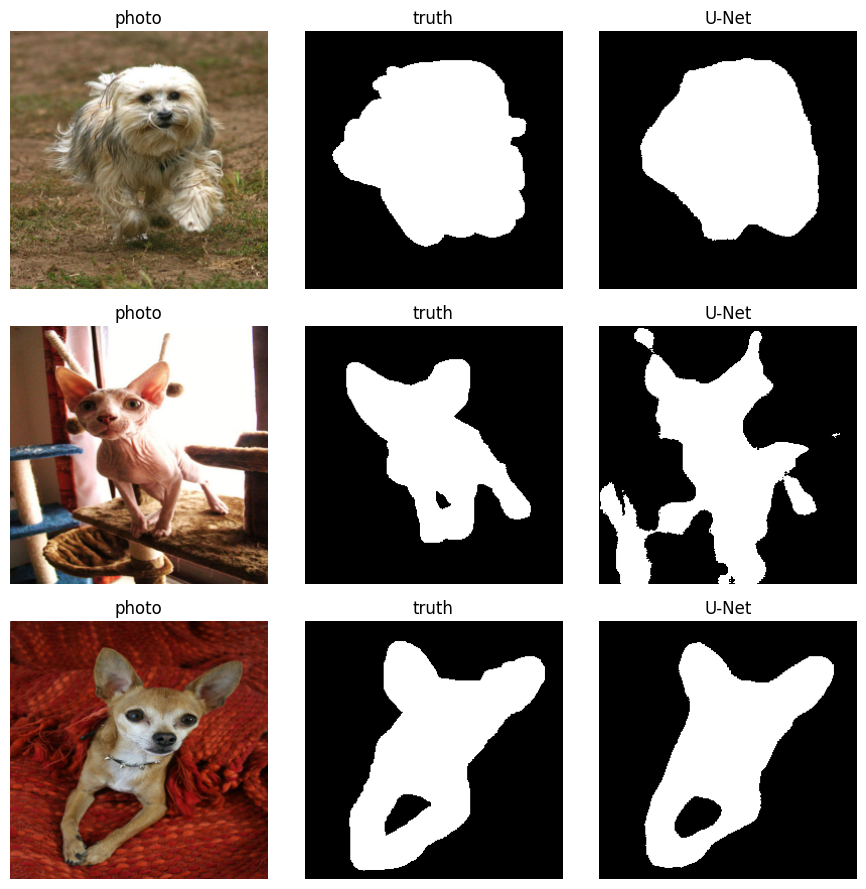

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for row in range(3):
    x, y = test_set[row]
    with torch.no_grad():
        pred = torch.sigmoid(model(x.unsqueeze(0).to(device)))[0, 0].cpu() > 0.5
    photo = x * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]
    panels = (photo.clamp(0, 1).permute(1, 2, 0), y[0], pred.float())
    for ax, panel, title in zip(axes[row], panels, ("photo", "truth", "U-Net")):
        ax.imshow(panel, cmap="gray")
        ax.set_title(title)
        ax.axis("off")
plt.tight_layout()
plt.show()

### Exercise 1: Effect of 90-Degree Rotation on ResNet-50 and ViT-B/16
We will define a modified evaluation function that applies a 90-degree rotation (`TF.rotate(img, 90)`) to each validation image after its standard pre-processing transformations.

In [ ]:
import time
import torch
import torch.nn as nn
import torchvision.transforms.functional as TF
from torchvision.models import resnet50, ResNet50_Weights, vit_b_16, ViT_B_16_Weights
from torchvision.datasets import Imagenette

device = "cuda" if torch.cuda.is_available() else "cpu"
IMAGENETTE_TO_IMAGENET = [0, 217, 482, 491, 497, 566, 569, 571, 574, 701]

zoo = {
    "ResNet-50": (resnet50(weights=ResNet50_Weights.IMAGENET1K_V2), ResNet50_Weights.IMAGENET1K_V2),
    "ViT-B/16": (vit_b_16(weights=ViT_B_16_Weights.IMAGENET1K_V1), ViT_B_16_Weights.IMAGENET1K_V1),
}

def evaluate(name, n_images=500):
    net, w = zoo[name]
    net = net.to(device).eval()
    data = Imagenette("data", split="val", size="160px", download=True, transform=w.transforms())
    g = torch.Generator().manual_seed(0)
    chosen = torch.randperm(len(data), generator=g)[:n_images].tolist()
    keep = torch.tensor(IMAGENETTE_TO_IMAGENET, device=device)
    correct = 0
    t0 = time.perf_counter()
    with torch.no_grad():
        for start in range(0, n_images, 50):
            batch = [data[i] for i in chosen[start:start + 50]]
            x = torch.stack([b[0] for b in batch]).to(device)
            y = torch.tensor([b[1] for b in batch], device=device)
            scores = net(x)[:, keep]
            correct += (scores.argmax(dim=1) == y).sum().item()
    ms = (time.perf_counter() - t0) / n_images * 1e3
    return correct / n_images, ms

def evaluate_rotated(name, n_images=500):
    net, w = zoo[name]
    net = net.to(device).eval()
    data = Imagenette("data", split="val", size="160px", download=True, transform=w.transforms())
    g = torch.Generator().manual_seed(0)
    chosen = torch.randperm(len(data), generator=g)[:n_images].tolist()
    keep = torch.tensor(IMAGENETTE_TO_IMAGENET, device=device)
    correct = 0
    with torch.no_grad():
        for start in range(0, n_images, 50):
            batch = [data[i] for i in chosen[start:start + 50]]
            x = torch.stack([TF.rotate(b[0], 90) for b in batch]).to(device)
            y = torch.tensor([b[1] for b in batch], device=device)
            scores = net(x)[:, keep]
            correct += (scores.argmax(dim=1) == y).sum().item()
    return correct / n_images

print(f"{'Model':15s} | {'Original Acc':>12} | {'Rotated Acc':>12}")
print("-" * 47)
for name in zoo:
    orig_acc, _ = evaluate(name)
    rot_acc = evaluate_rotated(name)
    print(f"{name:15s} | {orig_acc:>12.1%} | {rot_acc:>12.1%}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 177MB/s]


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 301MB/s]


Model           | Original Acc |  Rotated Acc
-----------------------------------------------


100%|██████████| 99.0M/99.0M [00:17<00:00, 5.80MB/s]


ResNet-50       |       100.0% |        94.0%
ViT-B/16        |       100.0% |        83.4%


### Exercise 2: Frozen-backbone fine-tune of ResNet-50 on CIFAR-10
We will download CIFAR-10, resize the 32x32 images to 224x224 using standard ResNet transforms, and train only a new 10-class linear classifier for exactly one epoch.

In [ ]:
import copy
from torch.utils.data import DataLoader
from torchvision.datasets import CIFAR10

def run_exercise_2():
    # Get pretrained ResNet-50
    pretrained, w = zoo["ResNet-50"]
    net = copy.deepcopy(pretrained).cpu()

    # Replace head
    net.fc = nn.Linear(net.fc.in_features, 10)

    # Freeze backbone
    for p in net.parameters():
        p.requires_grad = False
    for p in net.fc.parameters():
        p.requires_grad = True

    net = net.to(device)
    opt = torch.optim.AdamW(net.fc.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss()

    # Load CIFAR-10 resized to 224x224
    transforms = w.transforms()
    train_data = CIFAR10("data", train=True, download=True, transform=transforms)
    test_data = CIFAR10("data", train=False, download=True, transform=transforms)

    # Evaluate on a subset of 1000 training/testing for quick execution
    g = torch.Generator().manual_seed(0)
    train_sub = torch.utils.data.Subset(train_data, torch.randperm(len(train_data), generator=g)[:2000].tolist())
    test_sub = torch.utils.data.Subset(test_data, torch.randperm(len(test_data), generator=g)[:1000].tolist())

    train_loader = DataLoader(train_sub, batch_size=32, shuffle=True)
    test_loader = DataLoader(test_sub, batch_size=32)

    # Train 1 epoch
    net.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = loss_fn(net(x), y)
        opt.zero_grad()
        loss.backward()
        opt.step()

    # Eval
    net.eval()
    correct = 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            correct += (net(x).argmax(dim=1) == y).sum().item()

    print(f"CIFAR-10 1-Epoch Frozen Backbone Accuracy: {correct / len(test_sub):.1%}")

run_exercise_2()

100%|██████████| 170M/170M [24:37<00:00, 115kB/s]


CIFAR-10 1-Epoch Frozen Backbone Accuracy: 65.1%


### Exercise 3: Confidence Sweep (0.05 to 0.9) on YOLO
We sweep YOLO's confidence threshold, plotting both the total number of predicted boxes and the fraction matching ground truth at IoU >= 0.5.

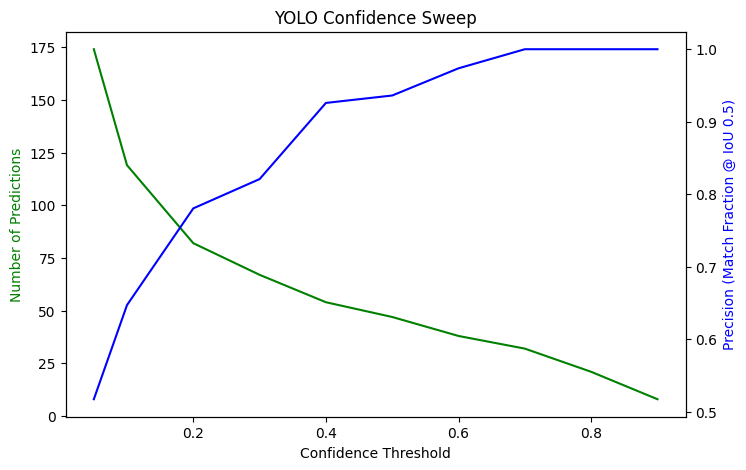

In [ ]:
def run_exercise_3():
    thresholds = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
    n_predictions = []
    match_fractions = []

    for conf in thresholds:
        results = det.predict([str(f) for f in files], conf=conf, verbose=False)
        preds = 0
        matches = 0
        for r in results:
            h, w = r.orig_shape
            truth = load_truth(label_dir / (Path(r.path).stem + ".txt"), h, w)
            for box, cls in zip(r.boxes.xyxy.tolist(), r.boxes.cls.tolist()):
                best = max((iou(box, t) for c, t in truth if c == int(cls)), default=0.0)
                preds += 1
                matches += (best >= 0.5)
        n_predictions.append(preds)
        match_fractions.append(matches / preds if preds > 0 else 0)

    fig, ax1 = plt.subplots(figsize=(8, 5))
    ax2 = ax1.twinx()
    ax1.plot(thresholds, n_predictions, 'g-', label='Num Predictions')
    ax2.plot(thresholds, match_fractions, 'b-', label='Match Fraction')
    ax1.set_xlabel('Confidence Threshold')
    ax1.set_ylabel('Number of Predictions', color='g')
    ax2.set_ylabel('Precision (Match Fraction @ IoU 0.5)', color='b')
    plt.title("YOLO Confidence Sweep")
    plt.show()

run_exercise_3()

### Exercise 4: Training U-Net with BCE, Dice, and Combined Losses
We define three training and validation passes to compare BCE, Dice, and combined loss optimization strategies.

In [ ]:
import segmentation_models_pytorch as smp
import torch
import torch.nn as nn
import numpy as np
import torchvision.transforms.functional as TF
from torch.utils.data import DataLoader
from torchvision.datasets import OxfordIIITPet

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
SIZE = 256

class PetMasks(torch.utils.data.Dataset):
    def __init__(self, split, n):
        self.ds = OxfordIIITPet("data", split=split, download=True, target_types="segmentation")
        g = torch.Generator().manual_seed(0)
        self.chosen = torch.randperm(len(self.ds), generator=g)[:n].tolist()
    def __len__(self):
        return len(self.chosen)
    def __getitem__(self, i):
        img, trimap = self.ds[self.chosen[i]]
        img = TF.resize(img, [SIZE, SIZE])
        trimap = TF.resize(trimap, [SIZE, SIZE], interpolation=TF.InterpolationMode.NEAREST)
        x = TF.normalize(TF.to_tensor(img), MEAN, STD)
        pet = torch.from_numpy(np.array(trimap)) != 2
        return x, pet.float().unsqueeze(0)

train_set = PetMasks("trainval", 600)
test_set = PetMasks("test", 200)
train_loader = DataLoader(train_set, batch_size=16, shuffle=True)
test_loader = DataLoader(test_set, batch_size=16)

def train_eval_unet(loss_mode):
    m = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet", in_channels=3, classes=1).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    bce = nn.BCEWithLogitsLoss()
    dice_loss = smp.losses.DiceLoss(mode="binary", from_logits=True)

    for epoch in range(2):
        m.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            logits = m(x)
            if loss_mode == "bce":
                loss = bce(logits, y)
            elif loss_mode == "dice":
                loss = dice_loss(logits, y)
            else:
                loss = bce(logits, y) + dice_loss(logits, y)
            opt.zero_grad()
            loss.backward()
            opt.step()

    m.eval()
    tp = fp = fn = tn = 0
    with torch.no_grad():
        for x, y in test_loader:
            pred = torch.sigmoid(m(x.to(device))).cpu() > 0.5
            y = y.bool()
            tp += (pred & y).sum().item()
            fp += (pred & ~y).sum().item()
            fn += (~pred & y).sum().item()
            tn += (~pred & ~y).sum().item()

    d_score = dice(tp+fp, tp+fn, tp)
    i_score = iou_from_counts(tp+fp, tp+fn, tp)
    print(f"{loss_mode.upper()} Loss -> Test Dice: {d_score:.4f}, IoU: {i_score:.4f}")

for mode in ["bce", "dice", "combined"]:
    train_eval_unet(mode)

100%|██████████| 792M/792M [00:39<00:00, 20.0MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 13.0MB/s]


BCE Loss -> Test Dice: 0.8577, IoU: 0.7509
DICE Loss -> Test Dice: 0.8684, IoU: 0.7675
COMBINED Loss -> Test Dice: 0.8835, IoU: 0.7913


### Exercise 5: Cutting training data size (1000 to 100 to 20)
We track how dataset scale affects full vs. frozen backbones.

In [ ]:
import copy
import torch
import torch.nn as nn
import time
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import Imagenette

def finetune_local(name, full, train_n=1000, epochs=2):
    pretrained, w = zoo[name]
    net = copy.deepcopy(pretrained).cpu()
    if name == "ResNet-50":
        net.fc = nn.Linear(net.fc.in_features, 10)
        head = net.fc
    else:
        net.heads.head = nn.Linear(net.heads.head.in_features, 10)
        head = net.heads.head

    for p in net.parameters():
        p.requires_grad = full
    for p in head.parameters():
        p.requires_grad = True

    net = net.to(device)
    params = [p for p in net.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=1e-4 if full else 1e-3)
    loss_fn = nn.CrossEntropyLoss()
    data = Imagenette("data", split="train", size="160px", download=True, transform=w.transforms())
    g = torch.Generator().manual_seed(0)
    chosen = torch.randperm(len(data), generator=g)[:train_n].tolist()
    loader = DataLoader(Subset(data, chosen), batch_size=16, shuffle=True)

    for epoch in range(epochs):
        net.train(full)
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(net(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
    return net, w

def evaluate_ft_local(net, w, n_images=500):
    data = Imagenette("data", split="val", size="160px", transform=w.transforms())
    g = torch.Generator().manual_seed(0)
    chosen = torch.randperm(len(data), generator=g)[:n_images].tolist()
    net.eval()
    correct = 0
    with torch.no_grad():
        for start in range(0, n_images, 50):
            batch = [data[i] for i in chosen[start:start + 50]]
            x = torch.stack([b[0] for b in batch]).to(device)
            y = torch.tensor([b[1] for b in batch], device=device)
            correct += (net(x).argmax(dim=1) == y).sum().item()
    return correct / n_images

for size in (100, 20):
    for full in (False, True):
        net, w = finetune_local("ResNet-50", full, train_n=size, epochs=2)
        acc = evaluate_ft_local(net, w)
        print(f"Dataset Size: {size:3d} | {'full' if full else 'frozen':8s} | Val Acc: {acc:.1%}")
        del net
        torch.cuda.empty_cache()

Dataset Size: 100 | frozen   | Val Acc: 64.4%
Dataset Size: 100 | full     | Val Acc: 66.8%
Dataset Size:  20 | frozen   | Val Acc: 36.8%
Dataset Size:  20 | full     | Val Acc: 14.4%


### Exercise 6: Fine-tuning YOLO with freeze=0 and high learning rate
We compare pretrained performance against unconstrained training with an aggressively high learning rate.

In [ ]:
ft_unfrozen = YOLO("yolo11n.pt")
ft_unfrozen.train(data="coco128.yaml", epochs=3, imgsz=640, batch=16,
                 freeze=0, optimizer="AdamW", lr0=1e-2,
                 project="runs", name="coco128_unfrozen", exist_ok=True,
                 plots=False, verbose=False)
best_unfrozen = YOLO(str(ft_unfrozen.trainer.best))
after_unfrozen = best_unfrozen.val(data="coco128.yaml", plots=False, verbose=False)
print(f"mAP@0.5:0.95 with freeze=0, lr0=1e-2: {after_unfrozen.box.map:.3f}")

### Exercise 7: Training U-Net with frozen encoder
We freeze the entire encoder and optimize only the decoder parameters.

In [ ]:
import segmentation_models_pytorch as smp
import torch
import torch.nn as nn

def train_frozen_encoder():
    m = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet", in_channels=3, classes=1).to(device)
    for p in m.encoder.parameters():
        p.requires_grad = False

    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, m.parameters()), lr=1e-3)
    bce = nn.BCEWithLogitsLoss()
    dice_loss = smp.losses.DiceLoss(mode="binary", from_logits=True)

    # Ensure we have our datasets defined
    try:
        train_loader, test_loader
    except NameError:
        train_set = PetMasks("trainval", 600)
        test_set = PetMasks("test", 200)
        train_loader = DataLoader(train_set, batch_size=16, shuffle=True)
        test_loader = DataLoader(test_set, batch_size=16)

    for epoch in range(3):
        m.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            logits = m(x)
            loss = bce(logits, y) + dice_loss(logits, y)
            opt.zero_grad()
            loss.backward()
            opt.step()

    m.eval()
    tp = fp = fn = tn = 0
    with torch.no_grad():
        for x, y in test_loader:
            pred = torch.sigmoid(m(x.to(device))).cpu() > 0.5
            y = y.bool()
            tp += (pred & y).sum().item()
            fp += (pred & ~y).sum().item()
            fn += (~pred & y).sum().item()
            tn += (~pred & ~y).sum().item()

    print(f"Frozen Encoder -> Test Dice: {dice(tp+fp, tp+fn, tp):.4f}, IoU: {iou_from_counts(tp+fp, tp+fn, tp):.4f}")

train_frozen_encoder()

Frozen Encoder -> Test Dice: 0.9226, IoU: 0.8564


### Summary Table of Formulas and Experiments

| Quantity | Formula Used | Used in |
| :--- | :--- | :--- |
| **Softmax** | $P(y = c \mid \mathbf{x}) = \frac{e^{z_c}}{\sum_{j} e^{z_j}}$ | Experiment 2 |
| **Intersection over Union (IoU)** | $\text{IoU} = \frac{|A \cap B|}{|A \cup B|}$ | Experiments 1, 3 |
| **Dice Coefficient** | $\text{Dice} = \frac{2 |A \cap B|}{|A| + |B|}$ | Experiments 1, 4 |
| **Dice from IoU** | $\text{Dice} = \frac{2 \cdot \text{IoU}}{1 + \text{IoU}}$ | Experiment 4 |
| **Top-1 Accuracy** | $\text{Accuracy} = \frac{1}{N} \sum_{i=1}^{N} \mathbb{I}(\hat{y}_i = y_i)$ | Experiment 2 |
| **Precision** | $\text{Precision} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Positives}}$ | Experiment 3 |
| **Recall** | $\text{Recall} = \frac{\text{True Positives}}{\text{True Positives} + \text{False Negatives}}$ | Experiment 3 |
| **Mean Average Precision (mAP)** | $\text{mAP} = \frac{1}{C} \sum_{c=1}^{C} \text{AP}_c$ | Experiment 3 |
| **Mean IoU** | $\text{mIoU} = \frac{\text{IoU}_{\text{foreground}} + \text{IoU}_{\text{background}}}{2}$ | Experiment 4 |